# Accelerated electrons in STIX data


$$\gamma_{\rm obs}\;\xrightarrow{\text{thick target}}\;\delta=\gamma+1\;\xrightarrow{\text{leaky box}}\;\frac{\tau_a}{\tau_{\rm esc}}=\delta(\delta-1)$$

| Section | What we look at |
|---|---|
| 1 | Download STIX data |
| 2 | Light curves: thermal vs. non-thermal - **Neupert effect** (cross-correlation and delay) |
| 3 | Spectrogram: pick the non-thermal peak |
| 4 | Fit thermal + power law → $T$, $\gamma$ |
| 5 | Interpret: $\gamma \to \delta \to \tau_a/\tau_{\rm esc}$ - **interactive leaky box** |
| 6 | Time evolution of $\gamma$: the soft–hard–soft pattern |

In [1]:
# Installs sunpy + stixpy in this kernel.
# Line 1 is the full install. Lines 2-3 are a fallback in case it fails
# (e.g. stixpy's optional dependency "pims" on Python 3.13): they install stixpy
# without optional dependencies. If line 1 worked, lines 2-3 change nothing.
# After the first install, restart the kernel before running the rest.
%pip install -q "sunpy[net]" stixpy
#%pip install -q "sunpy[net]"
#%pip install -q --no-deps stixpy

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import fits
from astropy.table import Table
from astropy.time import Time
from scipy.optimize import curve_fit

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "legend.frameon": False})

Note: you may need to restart the kernel to use updated packages.


## 1. Choose a flare and download the data

Two STIX Level-1 products:
* **Quick-look light curves** (`ql_lightcurve`): counts in 5 energy bands every 4 s.
* **Spectrogram** (`sci_xray_spec`): counts in 32 energy channels vs. time.

Any flare from the STIX flare list (https://datacenter.stix.i4ds.net/) works. Best: a C or low-M class flare without the attenuator inserted.

In [2]:
START, END = "2024-03-25T22:12", "2024-03-25T22:45"   # C4.7 flare, strong non-thermal emission

files_lc, files_spec = [], []

from sunpy.net import Fido, attrs as a
from stixpy.net.client import STIXClient  # noqa: F401  (registers the STIX client in Fido)
trange = a.Time(START, END)
files_lc = list(Fido.fetch(Fido.search(trange, a.Instrument.stix, a.stix.DataProduct.ql_lightcurve), path="stix_data/{file}"))
files_spec = list(Fido.fetch(Fido.search(trange, a.Instrument.stix, a.stix.DataProduct.sci_xray_spec), path="stix_data/{file}"))

Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

solo_L1_stix-ql-lightcurve_20240325_V02.fits:   0%|          | 0.00/1.75M [00:00<?, ?B/s]

Files Downloaded:   0%|          | 0/2 [00:00<?, ?file/s]

solo_L1_stix-sci-xray-spec_20240325T194959-20240326T015501_V04_2403255576-61968.fits:   0%|          | 0.00/2.…

solo_L1_stix-sci-xray-spec_20240325T194959-20240326T015501_V02_2403255576-61968.fits:   0%|          | 0.00/2.…

In [3]:
# Reader for STIX Level-1 FITS files
def read_stix_l1(path):
    # Minimal reader for STIX L1 FITS files (QL light curves and spectrograms).
    with fits.open(path) as hdul:
        t0 = Time(hdul[0].header["DATE-BEG"])
        data, ener = Table(hdul["DATA"].data), Table(hdul["ENERGIES"].data) # start time of the file
        tunit = u.Unit(hdul["DATA"].columns["time"].unit or "cs") # times are stored in centiseconds
    return dict(t=t0 + (np.asarray(data["time"], float) * tunit).to(u.s), # absolute time of each bin
                dt=(np.asarray(data["timedel"], float) * tunit).to_value(u.s), # duration of each bin [s]
                counts=np.asarray(data["counts"], float), # counts[time, energy channel]
                e_lo=np.asarray(ener["e_low"], float), e_hi=np.asarray(ener["e_high"], float), # channel edges [keV]
                rcr=np.asarray(data["rcr"]).astype(int).ravel())   # rcr > 0: attenuator / rate control active

# Instrument and physics models used later in the fit
def efficiency(eps):
    # Rough detection efficiency (windows at low energy, 1 mm CdTe at high energy). Illustrative only.
    return np.exp(-(6.5 / eps)**3) * (1 - np.exp(-(90.0 / eps)**2.5))

def photon_model(eps, A_th, kT, A_nt, gamma):
    # Photon spectrum per keV: thermal bremsstrahlung (Kramers) + non-thermal power law, per keV
    return A_th * np.exp(-eps / kT) / (eps * np.sqrt(kT)) + A_nt * (eps / 20.0)**(-gamma)

# Read the downloaded files
lc = read_stix_l1(sorted(files_lc)[0]) # quick-look light curves (5 bands, 4 s)
sp = max((read_stix_l1(f) for f in files_spec), key=lambda s: len(s["t"])) # spectrogram: keep the longest file

# Keep only the flare time window 
def crop(d, start=START, end=END):
    # Quick-look files cover a whole day: keep only the chosen time window
    keep = (d["t"] >= Time(start)) & (d["t"] <= Time(end))
    return {k: (v[keep] if k in ("t", "dt", "counts", "rcr") else v) for k, v in d.items()}

lc, sp = crop(lc), crop(sp) 
print("Light curve points:", len(lc["t"]), "| spectrogram points:", len(sp["t"]))

Light curve points: 495 | spectrogram points: 805


## 2. Light curves: two populations in time

* **Low energies** (4–10, 10–15 keV): **gradual** → hot thermal plasma.
* **High energies** (25–50 keV and up): **impulsive** spikes → non-thermal electrons.
* **Neupert effect:** $\;dF_{\rm thermal}/dt \propto F_{\rm non\text{-}thermal}$ — the electrons heat the plasma.

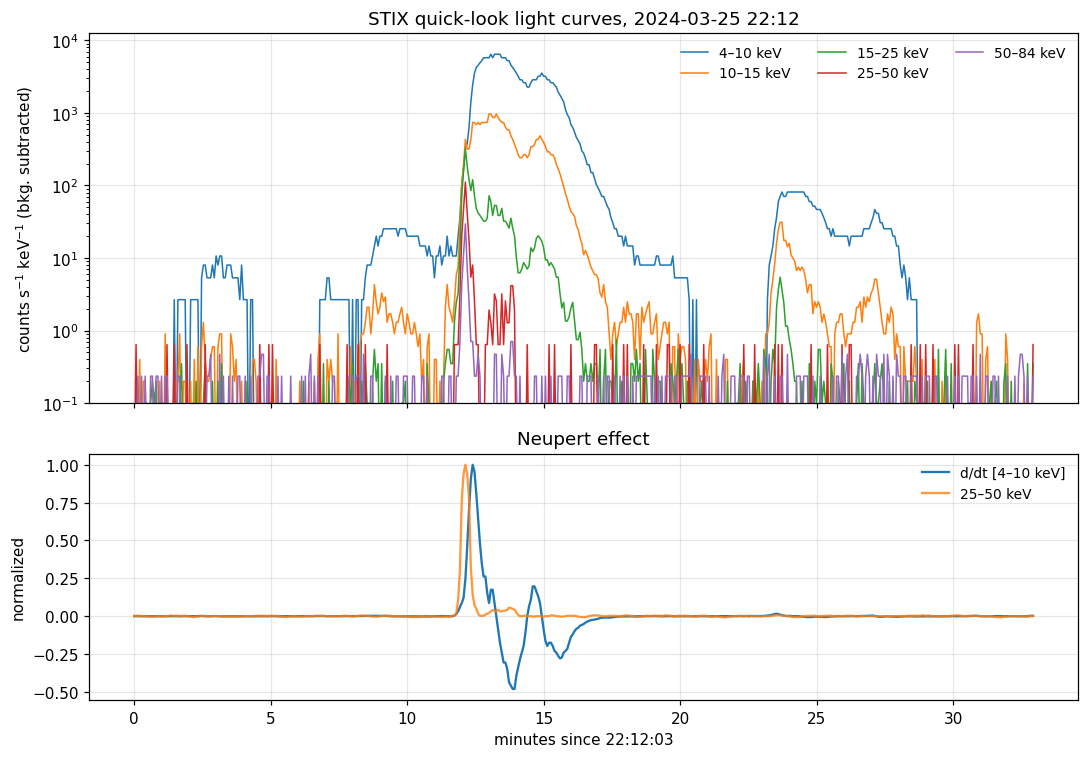

In [4]:
rate_lc = lc["counts"] / (lc["dt"][:, None] * (lc["e_hi"] - lc["e_lo"])[None, :])
# Background: STIX has an on-board calibration source (Ba-133, lines at 31 and 81 keV) that adds a
# constant background, strongest in the 25-50 and 50-84 keV bands. We take the first minutes as pre-flare level.
bkg_lc = np.nanmedian(rate_lc[: max(5, len(rate_lc) // 12)], axis=0)
rate_lc = rate_lc - bkg_lc
tmin = (lc["t"] - lc["t"][0]).to_value(u.min)
names = [f"{lo:g}–{hi:g} keV" for lo, hi in zip(lc["e_lo"], lc["e_hi"])]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw=dict(height_ratios=[3, 2]))
for j, name in enumerate(names):
    ax1.semilogy(tmin, np.clip(rate_lc[:, j], 1e-2, None), lw=1, label=name)
ax1.set_ylim(1e-1, None)
if np.any(lc["rcr"] > 0):
    ax1.fill_between(tmin, 1e-2, 1e7, where=lc["rcr"] > 0, color="gray", alpha=0.2, label="attenuator in")
ax1.set(ylabel="counts s$^{-1}$ keV$^{-1}$ (bkg. subtracted)", title=f"STIX quick-look light curves, {lc['t'][0].iso[:16]}")
ax1.legend(ncol=3, fontsize=9)

smooth = lambda y: np.convolve(y, np.ones(5) / 5, mode="same")
dFdt = np.gradient(smooth(rate_lc[:, 0]), tmin)
ax2.plot(tmin, dFdt / np.nanmax(dFdt), label=f"d/dt [{names[0]}]")
nth = smooth(rate_lc[:, 3])
ax2.plot(tmin, nth / np.nanmax(nth), alpha=0.8, label=names[3])
ax2.set(xlabel=f"minutes since {lc['t'][0].iso[11:19]}", ylabel="normalized", title="Neupert effect")
ax2.legend(fontsize=9)
fig.tight_layout(); plt.show()

### Quantifying the Neupert effect

If non-thermal electrons heat the plasma, the rate of change of the thermal emission should follow the non-thermal flux:
$$\frac{dF_{4-10\,\rm keV}}{dt}(t) \;\propto\; F_{25-50\,\rm keV}(t-\Delta t).$$

We compute the **cross-correlation** between both curves for different time shifts (lags):
* the **height** of the peak, $r$, tells how well the two curves match (1 = identical shape);
* the **position** of the peak, $\Delta t$, tells how long the thermal plasma takes to respond.

A positive lag means the plasma heats up after the electrons deposit their energy: chromospheric evaporation needs time to fill the loop. The lag resolution is 4 s, the quick-look cadence.

Max correlation r = 0.75 at lag = +16 s  (cadence 4 s)


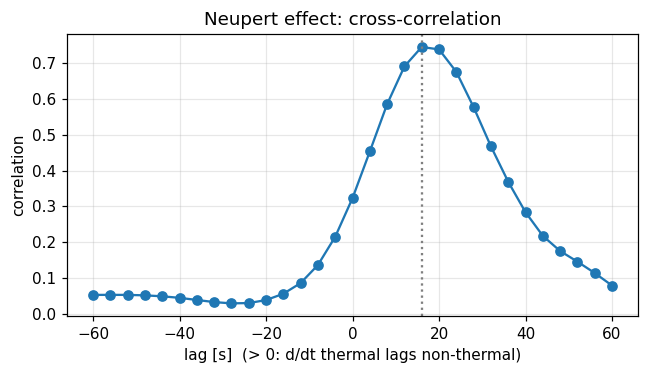

In [5]:
# Neupert effect, quantified: cross-correlation between d/dt(4-10 keV) and 25-50 keV
x = smooth(rate_lc[:, 3]) # non-thermal flux
y = np.gradient(smooth(rate_lc[:, 0]), tmin * 60) # time derivative of thermal flux
x, y = (x - x.mean()) / x.std(), (y - y.mean()) / y.std()
cadence = np.median(np.diff(tmin)) * 60 # seconds per sample (4 s for quick-look)
n = len(x)
lags = np.arange(-15, 16) # in samples; lag > 0: thermal derivative comes later
cc = np.array([np.mean(x[max(0, -k): n - max(0, k)] * y[max(0, k): n - max(0, -k)]) for k in lags])
best = lags[np.argmax(cc)]
print(f"Max correlation r = {cc.max():.2f} at lag = {best * cadence:+.0f} s  (cadence {cadence:.0f} s)")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(lags * cadence, cc, "o-")
ax.axvline(best * cadence, color="gray", ls=":")
ax.set(xlabel="lag [s]  (> 0: d/dt thermal lags non-thermal)", ylabel="correlation", title="Neupert effect: cross-correlation")
fig.tight_layout(); plt.show()

## 3. Spectrogram: choose the time interval

We fit around the **peak of the 25–50 keV emission**, only where the attenuator is out (`rcr = 0`), and subtract the pre-flare background.

Spectrogram starts at 2024-03-25 22:12:00.938 - the first minutes are used as background, so they should be pre-flare.


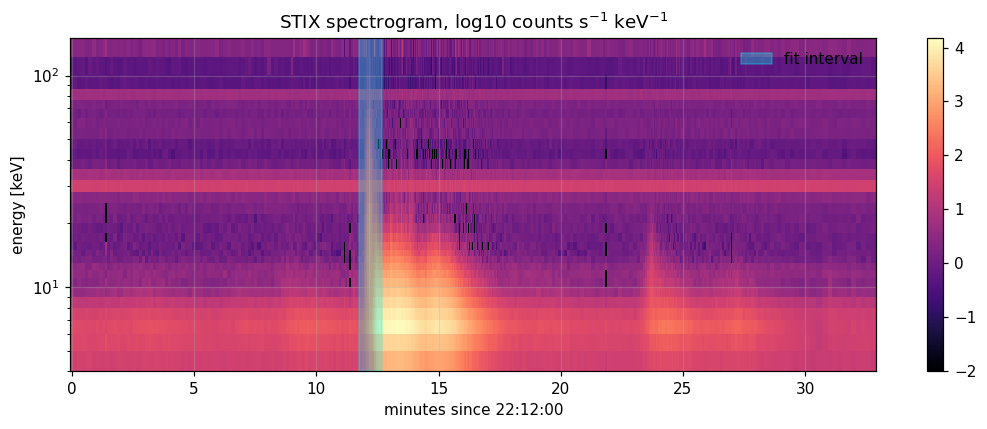

Fit interval: 2024-03-25 22:23:44.988 to 2024-03-25 22:24:41.488


In [6]:
dE = sp["e_hi"] - sp["e_lo"]
dE = np.where(np.isfinite(dE) & (dE > 0), dE, np.nan)
rate_sp = sp["counts"] / (sp["dt"][:, None] * dE[None, :])
tsp = (sp["t"] - sp["t"][0]).to_value(u.min)
e_mid = 0.5 * (sp["e_lo"] + np.where(np.isfinite(sp["e_hi"]), sp["e_hi"], 1.2 * sp["e_lo"]))

nth_band = (sp["e_lo"] >= 25) & (sp["e_hi"] <= 50)
nth_curve = sp["counts"][:, nth_band].sum(axis=1) / sp["dt"]
ok = np.where(sp["rcr"] == 0)[0]
i_peak = ok[np.argmax(nth_curve[ok])]
HALF_WIDTH = 30 # seconds on each side of the non-thermal peak (STIX time bins can be ~1 s during flares)
t_rel = (sp["t"] - sp["t"][i_peak]).to_value(u.s)
window = (np.abs(t_rel) <= HALF_WIDTH) & (sp["rcr"] == 0)

import warnings
with warnings.catch_warnings(): # the last channel (150 keV - inf) has no finite width: all-NaN, harmless
    warnings.simplefilter("ignore", RuntimeWarning)
    background = np.nanmedian(rate_sp[: max(5, len(tsp) // 15)], axis=0)
print("Spectrogram starts at", sp["t"][0].iso, "- the first minutes are used as background, so they should be pre-flare.")

fig, ax = plt.subplots(figsize=(10, 4))
pc = ax.pcolormesh(tsp, e_mid, np.log10(np.clip(rate_sp.T, 1e-2, None)), shading="nearest", cmap="magma")
ax.axvspan(tsp[window][0], tsp[window][-1], color="cyan", alpha=0.3, label="fit interval")
ax.set(yscale="log", ylim=(4, 150), xlabel=f"minutes since {sp['t'][0].iso[11:19]}", ylabel="energy [keV]",
       title="STIX spectrogram, log10 counts s$^{-1}$ keV$^{-1}$")
fig.colorbar(pc, ax=ax); ax.legend(loc="upper right")
fig.tight_layout(); plt.show()
print("Fit interval:", sp["t"][window][0].iso, "to", sp["t"][window][-1].iso)

## 4. Spectral fit: thermal + power law

$$C(\varepsilon) = \Big[\tfrac{A_{\rm th}}{\sqrt{k_BT}}\tfrac{e^{-\varepsilon/k_BT}}{\varepsilon} + A_{\rm nt}\,(\varepsilon/20\,{\rm keV})^{-\gamma}\Big]\times\eta(\varepsilon)$$

>**Teaching approximation:** $\eta(\varepsilon)$ is a rough efficiency. A publishable fit uses the full STIX spectral response matrix (OSPEX or `sunkit-spex`). The physics logic is the same.

Integration time: 60 s over 76 time bins
T = 19.2 ± 0.5 MK
gamma = 2.46 ± 0.02


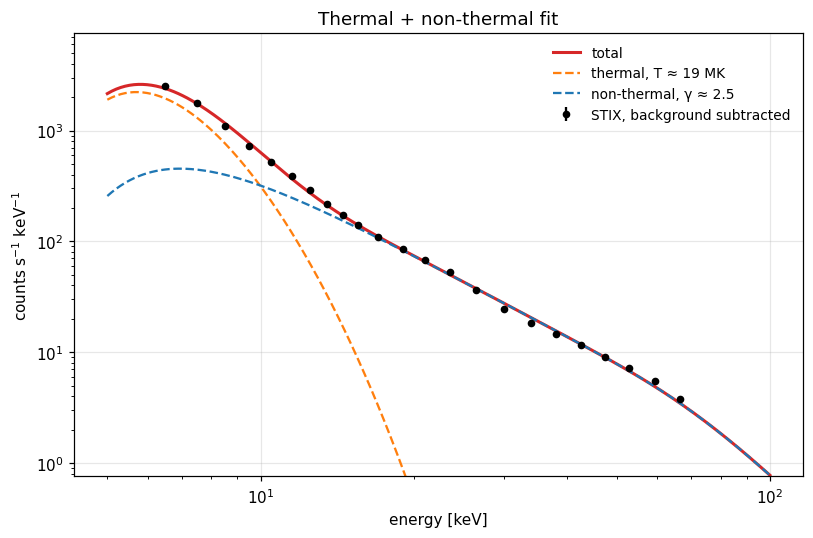

In [7]:
# Spectrum in the fit window: count rate per keV, background subtracted 
T_int = sp["dt"][window].sum() # total integration time [s]
N_cts = sp["counts"][window].sum(axis=0) # total counts per channel
C = N_cts / (T_int * dE) - background # count rate [counts s^-1 keV^-1] minus pre-flare level
err = np.sqrt(N_cts) / (T_int * dE) # Poisson error: sqrt(N), in the same units
print(f"Integration time: {T_int:.0f} s over {window.sum()} time bins")
err = np.sqrt(err**2 + (0.03 * np.abs(C))**2) # add 3% systematic error (our efficiency is only approximate)
use = (e_mid >= 6) & (e_mid <= 70) & np.isfinite(C) & (C > 3 * err) # channels to fit: 6-70 keV with signal > 3 sigma

# Model in count space: photon spectrum x detector efficiency
def count_model(eps, logA_th, kT, logA_nt, gamma): 
    # Amplitudes are fitted as log10 because they span many orders of magnitude
    return photon_model(eps, 10**logA_th, kT, 10**logA_nt, gamma) * efficiency(eps)

# Fit: initial guess, physical bounds, weighted least squares
p0 = [np.log10(np.nanmax(C) * 10), 1.5, np.log10(max(C[np.argmin(abs(e_mid - 20))], 1e-2)), 4.0]
popt, pcov = curve_fit(count_model, e_mid[use], C[use], p0=p0, sigma=err[use], absolute_sigma=True,
                       bounds=([-5, 0.3, -5, 1.5], [15, 5, 10, 10]), maxfev=20000)
logA_th, kT, logA_nt, gamma = popt
perr = np.sqrt(np.diag(pcov)) # 1-sigma uncertainties from the covariance matrix
print(f"T = {kT*11.6045:.1f} ± {perr[1]*11.6045:.1f} MK") # 1 keV = 11.6045 MK
print(f"gamma = {gamma:.2f} ± {perr[3]:.2f}")

#Plot: data, total model and its two components
eps = np.geomspace(5, 100, 300)
# fine energy grid for smooth model curves
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.errorbar(e_mid[use], C[use], yerr=err[use], fmt="o", ms=4, color="k", label="STIX, background subtracted")
ax.loglog(eps, count_model(eps, *popt), "C3", lw=2, label="total")
ax.loglog(eps, count_model(eps, logA_th, kT, -10, gamma), "C1--", label=f"thermal, T ≈ {kT*11.6:.0f} MK")
ax.loglog(eps, count_model(eps, -10, kT, logA_nt, gamma), "C0--", label=f"non-thermal, γ ≈ {gamma:.1f}")
ax.set(ylim=(np.nanmin(C[use]) / 5, np.nanmax(C) * 3), xlabel="energy [keV]", ylabel="counts s$^{-1}$ keV$^{-1}$",
       title="Thermal + non-thermal fit")
ax.legend(fontsize=9); fig.tight_layout(); plt.show()

## 5. From the spectrum back to the acceleration

In [8]:
delta = gamma + 1
ratio = delta * (delta - 1)
print(f"Photon index (STIX): gamma = {gamma:.2f}")
print(f"Electron index (thick target): delta = gamma + 1 = {delta:.2f}")
print(f"Leaky box:  tau_a / tau_esc = delta (delta - 1) = {ratio:.1f}")

Photon index (STIX): gamma = 2.46
Electron index (thick target): delta = gamma + 1 = 3.46
Leaky box:  tau_a / tau_esc = delta (delta - 1) = 8.5


### Interactive: which acceleration reproduces the data?

In the leaky-box model (slide 19), electrons injected at $E_0$ diffuse in energy and escape after $\tau_{\rm esc}$. The steady state is a broken power law:
$$N(E)\propto\begin{cases}E^{-\delta}, & E>E_0\\ E^{-\delta'}, & E<E_0\end{cases}\qquad
\delta,\delta' = \tfrac12 \pm\sqrt{\tfrac14+\tfrac{\tau_a}{\tau_{\rm esc}}}.$$

The part below $E_0$ comes from electrons that *lost* energy in the random walk before escaping.

**Move the slider** until the blue curve matches the dashed line from the STIX fit. That value of $\tau_a/\tau_{\rm esc}$ is the competition of time scales that produced the observed spectrum. (The slider starts at 2: thick-target $\gamma=\delta-1$ only makes sense for $\delta>2$.)

In [9]:
# Interactive leaky box: steady-state spectrum for a given tau_a / tau_esc, compared with the measured index
def leaky_box_spectrum(E, ratio):
    root = np.sqrt(0.25 + ratio)
    d_hi, d_lo = 0.5 + root, 0.5 - root  # power-law indices above / below injection E0
    return np.where(E >= 1, E**(-d_hi), E**(-d_lo)), d_hi

E = np.geomspace(0.1, 1e3, 400) # energy in units of the injection energy E0
delta_obs = gamma + 1 # from the STIX fit (thick target)
N_obs, _ = leaky_box_spectrum(E, delta_obs * (delta_obs - 1))

def plot_leaky(ratio=5.0):
    N, d = leaky_box_spectrum(E, ratio)
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.loglog(E, N, lw=2, label=fr"$\tau_a/\tau_{{esc}}={ratio:.1f}$ → δ = {d:.2f}, γ = {d - 1:.2f}")
    ax.loglog(E, N_obs, "k--", lw=1, label=f"STIX: γ = {gamma:.2f} → τa/τesc = {delta_obs * (delta_obs - 1):.1f}")
    ax.set(ylim=(1e-12, 2), xlabel=r"$E/E_0$", ylabel="N(E) (normalized at E0)", title="Leaky-box steady state")
    ax.legend(fontsize=9); plt.show()

try:
    from ipywidgets import interact, FloatSlider
    interact(plot_leaky, ratio=FloatSlider(value=5.0, min=2, max=30, step=0.5, description="τa/τesc"))
except ImportError:                                          # no widgets available: show a few fixed values
    for r in (2, 6, 12):
        plot_leaky(r)

interactive(children=(FloatSlider(value=5.0, description='τa/τesc', max=30.0, min=2.0, step=0.5), Output()), _…

## 6. Time evolution: the soft–hard–soft pattern

So far we measured one spectrum at the peak. But acceleration is a dynamic process: we repeat the same fit in consecutive **4 s windows** across the impulsive phase, keeping only windows with significant 25–50 keV emission.

What to look for: a classic HXR result is that γ **drops** (harder spectrum) when the non-thermal flux peaks and **rises** (softer) as it decays, the soft–hard–soft pattern. In the leaky-box language, $\tau_a/\tau_{\rm esc}=\delta(\delta-1)$ is smallest at the peak: acceleration is most efficient relative to escape.

* The γ axis is inverted, so "harder" is up and γ(t) should mirror the light curve.
* Grey open circles mark fits stuck at the allowed limits; they are not reliable.
* The **trend** is robust; the absolute values of γ would shift with the full instrument response.

 t-t_peak [s]   gamma         T [MK]   tau_a/tau_esc
      -6       1.52 ± 0.02     40.5        3.8 
      -2       1.41 ± 0.01     48.7        3.4 
      +2       1.61 ± 0.01      3.5        4.2 
      +6       2.38 ± 0.02      3.5        8.0 
     +10       3.27 ± 0.03      6.8       14.0 
     +14       4.14 ± 0.03      5.0       21.3 


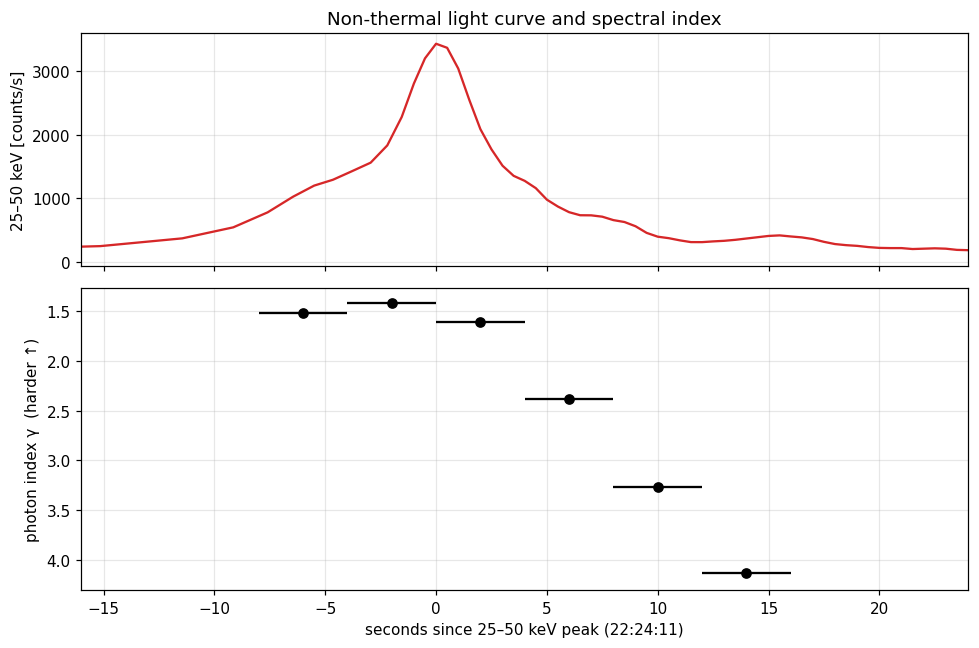

In [10]:
# Time windows around the non-thermal peak
STEP = 4 # seconds per window
MIN_NTH = 0.05 # skip windows where the 25-50 keV excess < 5% of its peak
edges = np.arange(-16, 24 + STEP, STEP) # window edges: from 16 s before to 24 s after the peak
t_peak = sp["t"][i_peak] # time of the 25-50 keV maximum (from section 3)
t_rel = (sp["t"] - t_peak).to_value(u.s) # time of each spectrogram bin relative to the peak [s]
nth_excess = nth_curve - np.nanmedian(nth_curve[: max(5, len(nth_curve) // 15)]) # 25-50 keV above pre-flare level

# Fit thermal + power law in each window (same method as section 4)
rows = []
for a, b in zip(edges[:-1], edges[1:]):
    sel = (t_rel >= a) & (t_rel < b) & (sp["rcr"] == 0) # bins in this window, attenuator out
    if sel.sum() == 0 or np.nanmean(nth_excess[sel]) < MIN_NTH * np.nanmax(nth_excess):
        continue  # no significant non-thermal emission: gamma is meaningless
    T_w = sp["dt"][sel].sum() # integration time of the window [s]
    N_w = sp["counts"][sel].sum(axis=0) # total counts per channel
    C_w = N_w / (T_w * dE) - background # count rate per keV, background subtracted
    e_w = np.sqrt(N_w / (T_w * dE)**2 + (0.03 * np.abs(C_w))**2) # Poisson + 3% systematic error
    use_w = (e_mid >= 6) & (e_mid <= 70) & np.isfinite(C_w) & (C_w > 3 * e_w) # channels with signal > 3 sigma
    if np.sum(use_w & (e_mid > 20)) < 4: # need enough non-thermal channels to measure gamma
        continue
    p, c = curve_fit(count_model, e_mid[use_w], C_w[use_w], p0=popt, sigma=e_w[use_w], # start from the peak fit
                         absolute_sigma=True, bounds=([-5, 0.3, -5, 1.0], [15, 5, 10, 10]), maxfev=20000) 
    rows.append((0.5 * (a + b), p[3], np.sqrt(c[3, 3]), p[1] * 11.6045)) # (window centre, gamma, error, T [MK])

# Results table: gamma -> delta -> tau_a/tau_esc in each window
t_c, g, g_err, T_MK = map(np.array, zip(*rows))
at_bound = (g < 1.05) | (g > 9.95) # fit stuck at the allowed limits -> not trustworthy
d = g + 1 # thick target: delta = gamma + 1
print(" t-t_peak [s]   gamma         T [MK]   tau_a/tau_esc")
for row, bad in zip(zip(t_c, g, g_err, T_MK, d * (d - 1)), at_bound):
    print("   {:+5.0f}       {:.2f} ± {:.2f}    {:5.1f}      {:5.1f}".format(*row), "  <- at fit limit" if bad else "")

# light curve (top) and gamma(t) (bottom)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.3]))
ax1.plot(t_rel, smooth(nth_curve), color="C3")
ax1.set(ylabel="25–50 keV [counts/s]", title="Non-thermal light curve and spectral index", xlim=(edges[0], edges[-1]))
ax2.errorbar(t_c[~at_bound], g[~at_bound], yerr=g_err[~at_bound], xerr=STEP / 2, fmt="o", color="k")
ax2.errorbar(t_c[at_bound], g[at_bound], xerr=STEP / 2, fmt="o", mfc="none", color="gray", label="at fit limit (unreliable)")
if at_bound.any():
    ax2.legend(fontsize=9)
ax2.invert_yaxis() # harder (smaller gamma) shown higher
ax2.set(xlabel=f"seconds since 25–50 keV peak ({t_peak.iso[11:19]})", ylabel="photon index γ  (harder ↑)")
fig.tight_layout(); plt.show()

**Reading the result:** in the leaky-box model, electrons escape the acceleration region ~$\tau_a/\tau_{\rm esc}$ times faster than they are accelerated. Only a few stay long enough to reach high energies, and that produces the power law.

### Try at home
1. Change `START`/`END` to another flare and compare γ.
2. Change `STEP` in section 6 (10 s, 30 s): how robust is the soft–hard–soft pattern?
3. Redo the fit with the STIX response matrix using `sunkit-spex`.

**References:** Brown (1971) *Sol. Phys.* 18, 489 · Neupert (1968) *ApJ* 153, L59 · Holman et al. (2011) *SSRv* 159, 107 · Petrosian (2012) *SSRv* 173, 535 · Krucker et al. (2020) *A&A* 642, A15